In [49]:
import os
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [51]:
!wget -q https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip -O uci_har.zip
!unzip -qo uci_har.zip -d uci_har
!unzip -qo "uci_har/UCI HAR Dataset.zip" -d uci_har

pasta_dataset = "uci_har/UCI HAR Dataset"

In [60]:
sensores = [
    "body_acc_x", "body_acc_y", "body_acc_z",
    "body_gyro_x", "body_gyro_y", "body_gyro_z",
    "total_acc_x", "total_acc_y", "total_acc_z"
]

In [61]:
def carregar_sinais(conjunto):
    sinais = [
        np.loadtxt(
            os.path.join(
                pasta_dataset,
                conjunto,
                "Inertial Signals",
                f"{sensor}_{conjunto}.txt"
            )
        )
        for sensor in sensores
    ]

    return np.stack(sinais, axis=2).astype("float32")

In [62]:
X_train = carregar_sinais("train")
X_test = carregar_sinais("test")

y_train = np.loadtxt(
    os.path.join(pasta_dataset, "train", "y_train.txt"),
    dtype=int
) - 1

y_test = np.loadtxt(
    os.path.join(pasta_dataset, "test", "y_test.txt"),
    dtype=int
) - 1

print("Formato dos dados de treinamento:", X_train.shape)
print("Formato dos dados de teste:", X_test.shape)

print("Formato dos rótulos de treinamento:", y_train.shape)
print("Formato dos rótulos de teste:", y_test.shape)

Formato dos dados de treinamento: (7352, 128, 9)
Formato dos dados de teste: (2947, 128, 9)
Formato dos rótulos de treinamento: (7352,)
Formato dos rótulos de teste: (2947,)


In [63]:
atividades = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

print("Distribuição no treinamento:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nDistribuição no teste:")
print(pd.Series(y_test).value_counts().sort_index())

Distribuição no treinamento:
0    1226
1    1073
2     986
3    1286
4    1374
5    1407
Name: count, dtype: int64

Distribuição no teste:
0    496
1    471
2    420
3    491
4    532
5    537
Name: count, dtype: int64


In [64]:
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Treinamento:", X_train_final.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

Treinamento: (5881, 128, 9)
Validação: (1471, 128, 9)
Teste: (2947, 128, 9)


In [65]:
tf.keras.utils.set_random_seed(42)

modelo_bilstm = Sequential([
    Input(shape=(128, 9)),

    Bidirectional(LSTM(64, return_sequences=True)),
    Dropout(0.3),

    Bidirectional(LSTM(32)),
    Dropout(0.3),

    Dense(32, activation="relu"),

    Dense(6, activation="softmax")
])

modelo_bilstm.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modelo_bilstm.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional_4 (Bidirectional) │ (None, 128, 128)       │        37,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,382 (317.90 KB)

 Trainable params: 81,382 (317.90 KB)

 Non-trainable params: 0 (0.00 B)

In [66]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

inicio = time.time()

historico = modelo_bilstm.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

tempo_treinamento = time.time() - inicio

print(f"Tempo de treinamento: {tempo_treinamento:.2f} segundos")

Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - accuracy: 0.5050 - loss: 1.1946 - val_accuracy: 0.6037 - val_loss: 0.9806
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.7092 - loss: 0.7386 - val_accuracy: 0.7838 - val_loss: 0.5099
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.8102 - loss: 0.4998 - val_accuracy: 0.8756 - val_loss: 0.3689
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.8561 - loss: 0.3892 - val_accuracy: 0.8484 - val_loss: 0.3804
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9039 - loss: 0.2668 - val_accuracy: 0.9368 - val_loss: 0.1954
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.9310 - loss: 0.1880 - val_accuracy: 0.9449 - val_loss: 0.1685
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.9379 - loss: 0.1668 - val_accuracy: 0.9497 - val_loss: 0.1511
Epoch 8/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - accuracy: 0.9396 - loss: 0.1544 - val_accuracy: 0.

In [67]:
perda_teste, acuracia_teste = modelo_bilstm.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Acurácia no teste: {acuracia_teste:.2%}")
print(f"Perda no teste: {perda_teste:.4f}")

Acurácia no teste: 90.06%
Perda no teste: 0.2969


In [72]:
y_pred_prob = modelo_bilstm.predict(X_test, verbose=0)

y_pred = np.argmax(y_pred_prob, axis=1)

acuracia = accuracy_score(y_test, y_pred)

precisao = precision_score(
    y_test, y_pred, average="macro"
)

recall = recall_score(
    y_test, y_pred, average="macro"
)

f1 = f1_score(
    y_test, y_pred, average="macro"
)

print(f"Acurácia: {acuracia:.4f}")
print(f"Precisão Macro: {precisao:.4f}")
print(f"Recall Macro: {recall:.4f}")
print(f"F1-score Macro: {f1:.4f}")

print("\nRelatório de classificação:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=atividades
    )
)

Acurácia: 0.9006
Precisão Macro: 0.9032
Recall Macro: 0.9013
F1-score Macro: 0.9007

Relatório de classificação:
                    precision    recall  f1-score   support

           Walking       0.89      0.93      0.91       496
  Walking Upstairs       1.00      0.85      0.92       471
Walking Downstairs       0.89      0.98      0.93       420
           Sitting       0.83      0.79      0.81       491
          Standing       0.81      0.85      0.83       532
            Laying       1.00      1.00      1.00       537

          accuracy                           0.90      2947
         macro avg       0.90      0.90      0.90      2947
      weighted avg       0.90      0.90      0.90      2947



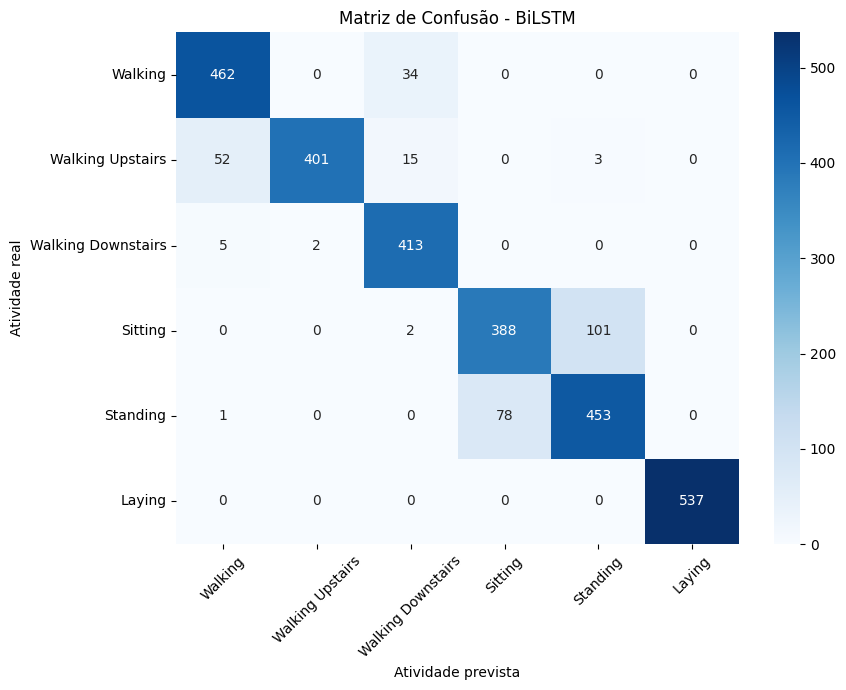

In [73]:
matriz = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=atividades,
    yticklabels=atividades
)

plt.title("Matriz de Confusão - BiLSTM")
plt.xlabel("Atividade prevista")
plt.ylabel("Atividade real")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

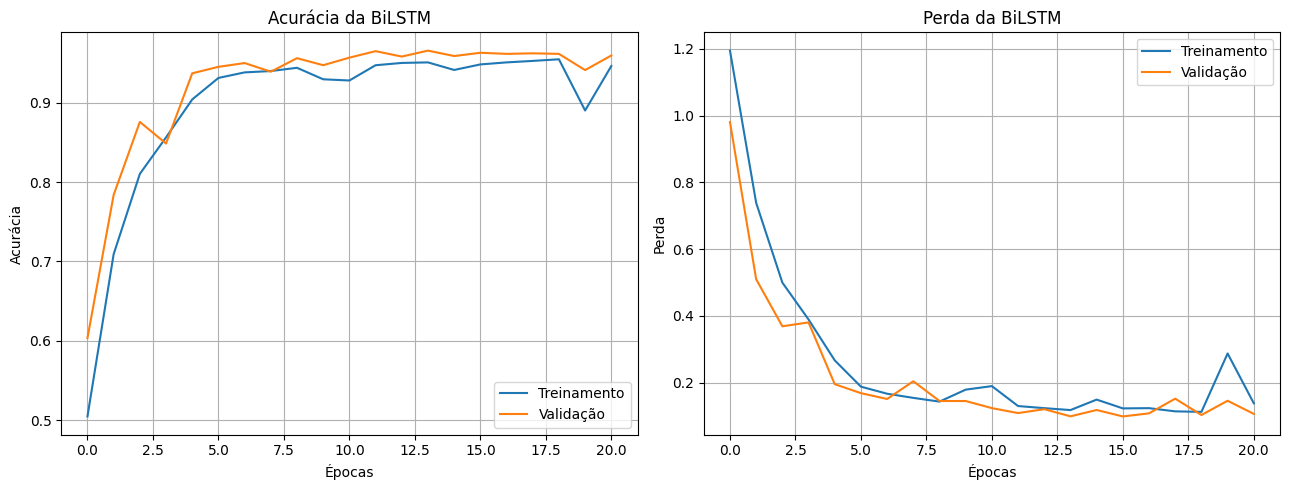

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Acurácia
axes[0].plot(
    historico.history["accuracy"],
    label="Treinamento"
)

axes[0].plot(
    historico.history["val_accuracy"],
    label="Validação"
)

axes[0].set_title("Acurácia da BiLSTM")
axes[0].set_xlabel("Épocas")
axes[0].set_ylabel("Acurácia")
axes[0].legend()
axes[0].grid(True)

# Perda
axes[1].plot(
    historico.history["loss"],
    label="Treinamento"
)

axes[1].plot(
    historico.history["val_loss"],
    label="Validação"
)

axes[1].set_title("Perda da BiLSTM")
axes[1].set_xlabel("Épocas")
axes[1].set_ylabel("Perda")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [75]:
modelo_bilstm.save("modelo_bilstm_uci_har.keras")

print("Modelo BiLSTM salvo com sucesso!")

Modelo BiLSTM salvo com sucesso!


In [76]:
!pip install -q shap

In [77]:
import shap

np.random.seed(42)

indices = np.random.choice(
    len(X_train_final),
    size=30,
    replace=False
)

background = X_train_final[indices]

amostras_shap = X_test[:5]

In [78]:
explainer_grad = shap.GradientExplainer(
    modelo_bilstm,
    background
)

valores_shap_grad = explainer_grad.shap_values(
    amostras_shap,
    nsamples=100
)

print("SHAP calculado!")
print("Formato dos valores SHAP:")
print(np.asarray(valores_shap_grad).shape)

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_15
Received: inputs=['Tensor(shape=(5, 128, 9))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_15
Received: inputs=['Tensor(shape=(50, 128, 9))']
  warnings.warn(msg)


SHAP calculado!
Formato dos valores SHAP:
(5, 128, 9, 6)


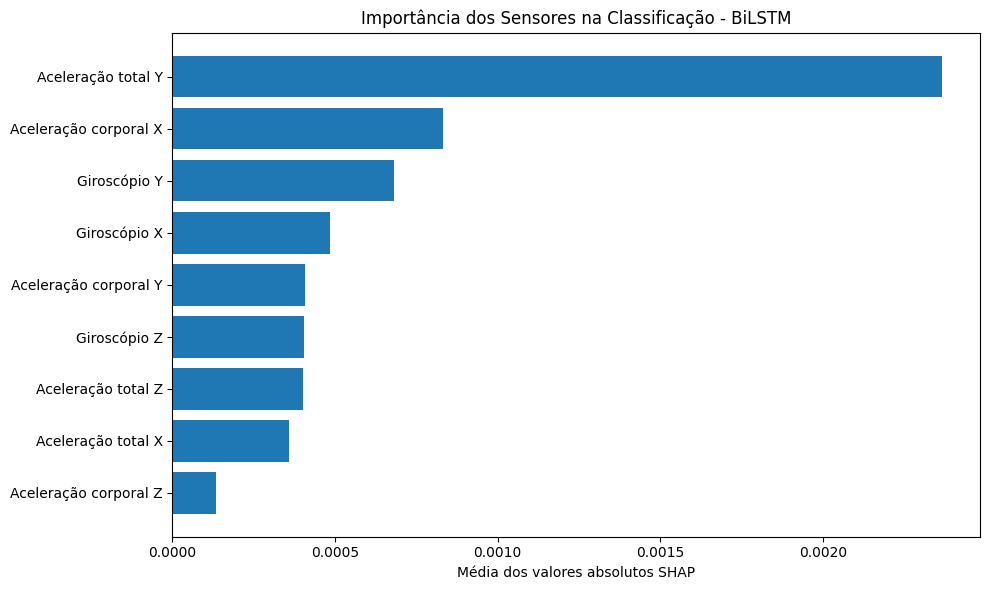

In [79]:
valores = np.asarray(valores_shap_grad)

previsoes_shap = modelo_bilstm.predict(
    amostras_shap,
    verbose=0
)

classes_previstas = np.argmax(
    previsoes_shap,
    axis=1
)

if isinstance(valores_shap_grad, list):
    valores = np.stack(valores_shap_grad, axis=-1)

if valores.ndim == 4 and valores.shape[-1] == 6:
    contribuicoes = np.stack([
        valores[i, :, :, classes_previstas[i]]
        for i in range(len(amostras_shap))
    ])

elif valores.ndim == 4 and valores.shape[1] == 6:
    contribuicoes = np.stack([
        valores[i, classes_previstas[i], :, :]
        for i in range(len(amostras_shap))
    ])

else:
    raise ValueError(
        f"Formato SHAP não esperado: {valores.shape}"
    )

importancia = np.mean(
    np.abs(contribuicoes),
    axis=(0, 1)
)

nomes_sensores = [
    "Aceleração corporal X",
    "Aceleração corporal Y",
    "Aceleração corporal Z",
    "Giroscópio X",
    "Giroscópio Y",
    "Giroscópio Z",
    "Aceleração total X",
    "Aceleração total Y",
    "Aceleração total Z"
]

ordem = np.argsort(importancia)

plt.figure(figsize=(10, 6))

plt.barh(
    np.array(nomes_sensores)[ordem],
    importancia[ordem]
)

plt.xlabel("Média dos valores absolutos SHAP")
plt.title("Importância dos Sensores na Classificação - BiLSTM")

plt.tight_layout()
plt.show()

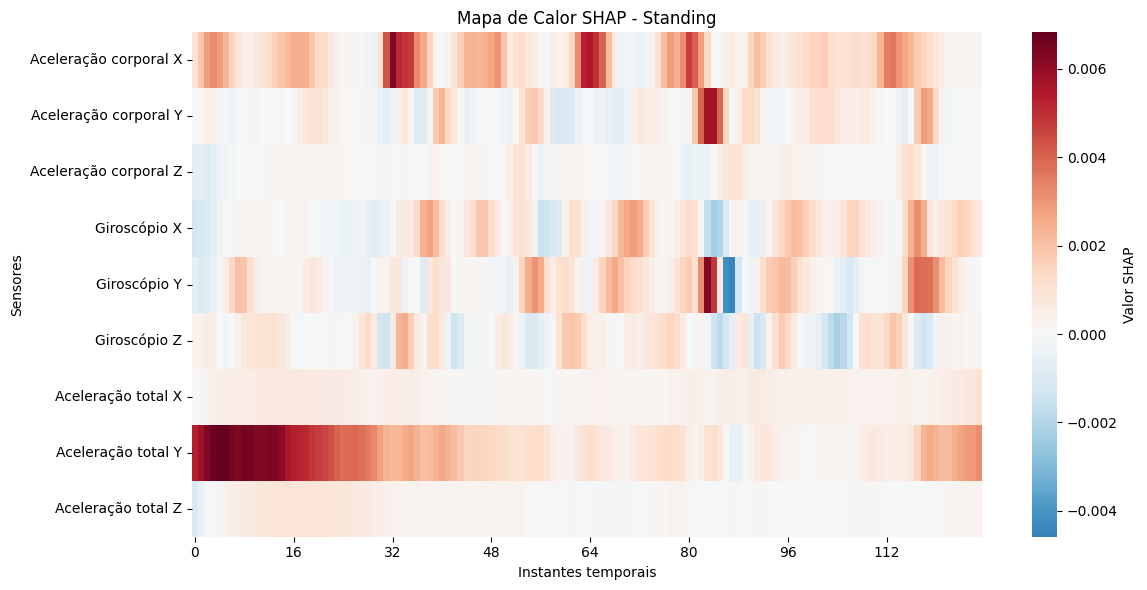

In [80]:
indice = 0

classe = classes_previstas[indice]

mapa_shap = contribuicoes[indice]

plt.figure(figsize=(12, 6))

sns.heatmap(
    mapa_shap.T,
    cmap="RdBu_r",
    center=0,
    xticklabels=16,
    yticklabels=nomes_sensores,
    cbar_kws={"label": "Valor SHAP"}
)

plt.title(
    f"Mapa de Calor SHAP - {atividades[classe]}"
)

plt.xlabel("Instantes temporais")
plt.ylabel("Sensores")

plt.tight_layout()
plt.show()